## Importing the data and chopping it to the regions with highest signal (the 48 hours post song release) and averaging the sentiment scores

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler


header = ['comment_id', 'text', 'date', 'song', 'artist', 'kendrick_score', 'drake_score']
dataset = pd.read_csv(filepath_or_buffer='./cleaned_comments/cleaned_comments.csv',  delimiter=',', names=header, skiprows=1)
dataset

,comment_id,text,date,song,artist,kendrick_score,drake_score
0,Ugzc5Srhx8p6qzdSjvB4AaABAg,Kendrick responded so fast I didnt know Drake ...,2024-05-04 12:59:37+00:00,Family_Matters,BagOnly_Drake,2,-1
1,UgxGl-mJYHo4mzjNy0R4AaABAg,Beat switches each time a different ghost writ...,2024-05-04 08:41:23+00:00,Family_Matters,BagOnly_Drake,0,-2
2,Ugw8sI-rRjgKXTUCBFV4AaABAg,Kendrick had a diss ready for this song not ev...,2024-05-04 05:18:35+00:00,Family_Matters,BagOnly_Drake,2,0
3,UgzkG6vRyh2O9FOlnJR4AaABAg,Imagine sitting down in a group and writing th...,2024-05-04 17:04:41+00:00,Family_Matters,BagOnly_Drake,1,-1
4,UgyRU5sH2RugrPSNal94AaABAg,ngl Drake's melody is fire\n\nbut Kendrick's l...,2024-05-05 06:28:06+00:00,Family_Matters,BagOnly_Drake,3,2
...,...,...,...,...,...,...,...
5693,Ugy_pfO-XFQhO5gGBA94AaABAg,"''I agree'' with you, this track is so deep th...",2024-05-05 10:59:39+00:00,Meet_the_Grahams,LostInVegas_Kendrick_Lamar,3,0
5694,UgwKaRbSQ7CT8Id9UlJ4AaABAg,"It's like y'all came in expecting a comedy, wa...",2024-05-04 21:19:33+00:00,Meet_the_Grahams,LostInVegas_Kendrick_Lamar,3,-3
5695,UgwKuRsl6mRT319BxZB4AaABAg,Kendrick gave you all the bars and metaphors y...,2024-05-05 05:00:26+00:00,Meet_the_Grahams,LostInVegas_Kendrick_Lamar,3,0
5696,UgxGzHrFJUiB4cJv-7t4AaABAg,Never thought I would think this channel would...,2024-05-04 22:54:04+00:00,Meet_the_Grahams,LostInVegas_Kendrick_Lamar,2,-2


In [ ]:
%matplotlib widget

#calculating the clean data table for times
times_data_table = dataset[['date', 'kendrick_score', 'drake_score']]
#making sure the dates are in date format
times_data_table['date'] = pd.to_datetime(times_data_table['date'], errors='coerce')

fine_ranges = [
    ('2024-03-21 00:00', '2024-03-23 00:00'), 
    ('2024-04-13 00:00', '2024-04-21 00:00'),
    ('2024-04-30 00:00', '2024-05-11 00:00'),
]

fine_cadence = '6h'
course_cadence = '7D'


#binning into courser intervals while disregarding 0 values for each individual artist (0=not mentioned in comment)
fine_sampling_mask = pd.Series(False, index=times_data_table.index)

for starttime, endtime in fine_ranges:
    start = pd.Timestamp(starttime).tz_localize("UTC")
    end = pd.Timestamp(endtime).tz_localize("UTC")

    fine_sampling_mask |= ( (start <= times_data_table['date']) & (times_data_table['date'] >= end))

finely_sampled_data = times_data_table[fine_sampling_mask]
coursely_sampled_data = times_data_table[~fine_sampling_mask]

#for kendrick
kdot_course_data = (coursely_sampled_data[coursely_sampled_data['kendrick_score'] != 0].set_index('date')['kendrick_score'].resample(course_cadence).mean())
kdot_fine_data = (finely_sampled_data[finely_sampled_data['kendrick_score'] != 0].set_index('date')['kendrick_score'].resample(fine_cadence).mean())
kdot_scores_over_time = pd.concat((kdot_course_data, kdot_fine_data)).sort_index()

#for drake
drake_course_data = (coursely_sampled_data[coursely_sampled_data['drake_score'] != 0].set_index('date')['drake_score'].resample(course_cadence).mean())
drake_fine_data = (finely_sampled_data[finely_sampled_data['drake_score'] != 0].set_index('date')['drake_score'].resample(fine_cadence).mean())
drake_scores_over_time = pd.concat((drake_course_data, drake_fine_data)).sort_index()

In [ ]:
#plotting the data sentiment data
plt.figure(figsize=(12, 5))
plt.plot(kdot_scores_over_time.index, kdot_scores_over_time.values, c='blue', label='Kendrick Average Score')
plt.plot(drake_scores_over_time.index, drake_scores_over_time.values, c='red', label='Drake Average Score')
plt.title("Sentiment Scores for Drake and Kendrick for the Beef Averaged Over the Sample")
plt.xlabel("Date Since Release of 'First Person Shooter'")
plt.ylabel("Sentiment Score\n(-3 = Strong Negative, +3 = Strong Positive)")

In [2]:
#pulling the data for Kendrick-biased channels
times_data_table = dataset[['artist', 'date', 'kendrick_score', 'drake_score']]
#making sure the dates are in date format
times_data_table['date'] = pd.to_datetime(times_data_table['date'], errors='coerce')

kendrick_biased_data = times_data_table.loc[times_data_table['artist'].isin(['Future', 'Kendrick_Lamar', 'KnoxHill_Drake', 'KnoxHill_Kendrick_Lamar'])]

#now, averaging the data together during times of release
fine_ranges = [
    ('2024-03-21 00:00', '2024-03-25 00:00'), 
    ('2024-04-13 00:00', '2024-04-17 00:00'),
    ('2024-04-30 00:00', '2024-05-08 00:00'),
]

fine_cadence = '3h'
# course_cadence = '7D'
kdot_fine_sampling_mask = pd.Series(False, index=kendrick_biased_data.index)

for starttime, endtime in fine_ranges:
    start = pd.Timestamp(starttime).tz_localize("UTC")
    end = pd.Timestamp(endtime).tz_localize("UTC")

    kdot_fine_sampling_mask |= ( (start <= kendrick_biased_data['date']) & (kendrick_biased_data['date'] <= end))

kdot_finely_sampled_data = kendrick_biased_data[kdot_fine_sampling_mask]

#for kendrick
kdot_biased_kdot_scores = (kdot_finely_sampled_data[kdot_finely_sampled_data['kendrick_score'] != 0].set_index('date')['kendrick_score'].resample(fine_cadence).mean())

#for drake
kdot_biased_drake_scores = (kdot_finely_sampled_data[kdot_finely_sampled_data['drake_score'] != 0].set_index('date')['drake_score'].resample(fine_cadence).mean())

In [3]:
drake_biased_data = times_data_table.loc[times_data_table['artist'].isin(['Drake', 'ScruFaceJean_Drake', 'LostInVegas_Drake', 'LostInVegas_Kendrick_Lamar'])]

#now, averaging the data together during times of release
drake_fine_sampling_mask = pd.Series(False, index=drake_biased_data.index)

for starttime, endtime in fine_ranges:
    start = pd.Timestamp(starttime).tz_localize("UTC")
    end = pd.Timestamp(endtime).tz_localize("UTC")

    drake_fine_sampling_mask |= ( (start <= drake_biased_data['date']) & (drake_biased_data['date'] <= end))

drake_finely_sampled_data = drake_biased_data[drake_fine_sampling_mask]

#for kendrick
drake_biased_kdot_scores = (drake_finely_sampled_data[drake_finely_sampled_data['kendrick_score'] != 0].set_index('date')['kendrick_score'].resample(fine_cadence).mean())

#for drake
drake_biased_drake_scores = (drake_finely_sampled_data[drake_finely_sampled_data['drake_score'] != 0].set_index('date')['drake_score'].resample(fine_cadence).mean())


Text(0, 0.5, 'Sentiment Score\n(-3 = Strong Negative, +3 = Strong Positive)')

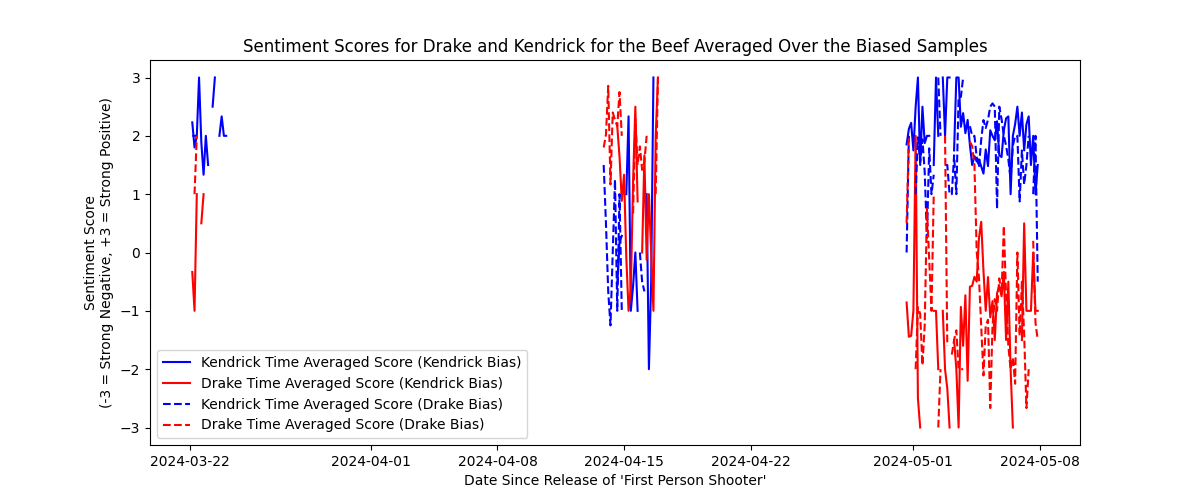

In [5]:
#visualizing the data
#plotting the data sentiment data
%matplotlib widget
plt.close('all'
)
plt.figure(figsize=(12, 5))
plt.plot(kdot_biased_kdot_scores.index, kdot_biased_kdot_scores.values, c='blue', label='Kendrick Time Averaged Score (Kendrick Bias)')
plt.plot(kdot_biased_drake_scores.index, kdot_biased_drake_scores.values, c='red', label='Drake Time Averaged Score (Kendrick Bias)')
plt.plot(drake_biased_kdot_scores.index, drake_biased_kdot_scores.values, c='blue', ls='--', label='Kendrick Time Averaged Score (Drake Bias)')
plt.plot(drake_biased_drake_scores.index, drake_biased_drake_scores.values, c='red', ls='--', label='Drake Time Averaged Score (Drake Bias)')
plt.legend(loc='best')
plt.title("Sentiment Scores for Drake and Kendrick for the Beef Averaged Over the Biased Samples")
plt.xlabel("Date Since Release of 'First Person Shooter'")
plt.ylabel("Sentiment Score\n(-3 = Strong Negative, +3 = Strong Positive)")

## Collecting just the biased sentiment scores and pairing kendrick and drake scores for each period into points for clustering

In [7]:
#splicing the data together into the format (Kendrick Score, Drake Score)

#for kendrick biased sources:
kdot_biased_scores = (
    kdot_finely_sampled_data
    .set_index('date')[['kendrick_score', 'drake_score']]
    .replace(0, np.nan).resample(fine_cadence).mean()
    .dropna(subset=['kendrick_score', 'drake_score'])
)
kdot_biased_scores['bias'] = 'Kendrick'

#for drake biased sources:
drake_biased_scores = (
    drake_finely_sampled_data
    .set_index('date')[['kendrick_score', 'drake_score']]
    .replace(0, np.nan).resample(fine_cadence).mean()
    .dropna(subset=['kendrick_score', 'drake_score'])
)
drake_biased_scores['bias'] = 'Drake'

combined_biased_dataset = pd.concat([kdot_biased_scores, drake_biased_scores])
combined_biased_dataset

,kendrick_score,drake_score,bias
date,,,
2024-03-22 03:00:00+00:00,2.230769,-0.333333,Kendrick
2024-03-22 06:00:00+00:00,1.800000,-1.000000,Kendrick
2024-03-22 09:00:00+00:00,2.000000,1.000000,Kendrick
2024-03-22 15:00:00+00:00,1.888889,0.500000,Kendrick
2024-03-22 18:00:00+00:00,1.333333,1.000000,Kendrick
...,...,...,...
2024-05-07 06:00:00+00:00,1.500000,-2.666667,Drake
2024-05-07 09:00:00+00:00,2.000000,-2.000000,Drake
2024-05-07 15:00:00+00:00,1.000000,0.200000,Drake


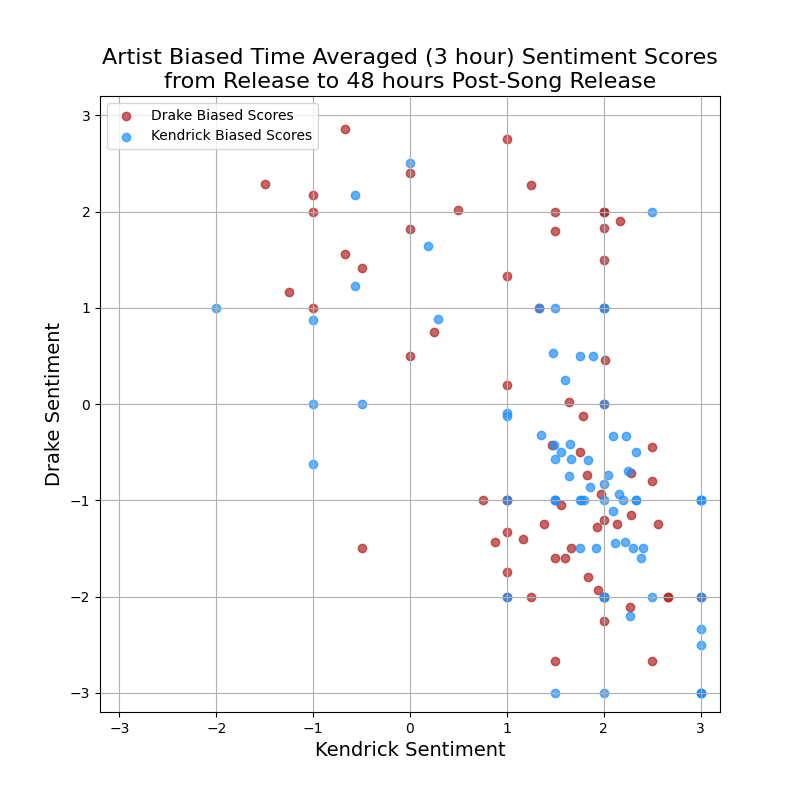

In [8]:
#scatter plotting the combined biased dataset

plt.close('all')
plt.figure(figsize=(8, 8))
drakebias = combined_biased_dataset['bias'] == 'Drake'
plt.scatter(combined_biased_dataset['kendrick_score'][drakebias], combined_biased_dataset['drake_score'][drakebias], c='firebrick', alpha=0.7, label='Drake Biased Scores')
kdotbias = combined_biased_dataset['bias'] == 'Kendrick'
plt.scatter(combined_biased_dataset['kendrick_score'][kdotbias], combined_biased_dataset['drake_score'][kdotbias], c='dodgerblue', alpha=0.7, label='Kendrick Biased Scores')
plt.ylabel("Drake Sentiment", fontsize=14)
plt.xlabel("Kendrick Sentiment", fontsize=14)
plt.legend(loc='best')
plt.xlim((-3.2, 3.2))
plt.ylim((-3.2, 3.2))
# plt.tight_layout()
plt.title("Artist Biased Time Averaged (3 hour) Sentiment Scores\nfrom Release to 48 hours Post-Song Release", fontsize=16)
plt.grid()
plt.show()

## Performing k-means clustering on time averaged sentiment data to observe if there's a noticable difference in the 

In [9]:
#STANDARDIZING ALL Sentiment Scores
X = StandardScaler().fit_transform(combined_biased_dataset[['kendrick_score', 'drake_score']])
X

array([[ 0.68593786,  0.08101932],
       [ 0.28786205, -0.38000766],
       [ 0.47268296,  1.00307326],
       [ 0.37000468,  0.65730303],
       [-0.14338674,  1.00307326],
       [ 0.01063068,  1.00307326],
       [ 1.39678752, -0.38000766],
       [ 0.47268296, -1.07154812],
       [ 0.47268296,  1.00307326],
       [-1.9035859 ,  1.80987047],
       [-1.20750715,  1.44636843],
       [-1.11149628,  0.92404007],
       [-0.4514216 ,  0.24866549],
       [ 0.78071781, -0.38000766],
       [-2.29963072, -0.12067998],
       [-1.9035859 ,  1.15674892],
       [-1.37552616,  2.04038395],
       [-2.29963072,  0.91663071],
       [-2.29963072,  0.3115328 ],
       [-0.4514216 ,  0.22509025],
       [-3.22373527,  1.00307326],
       [-1.83757844,  0.3115328 ],
       [ 1.39678752, -0.38000766],
       [ 0.33744815, -0.28121616],
       [ 0.58357551, -0.68735897],
       [ 0.67803953, -0.67638214],
       [ 0.24165682, -0.38000766],
       [ 0.93473524,  1.69461372],
       [ 1.39678752,

[286.0000000000001, 130.02005433806474, 80.25967129138114, 58.644383142273114, 48.897565798923296, 41.2264437390765, 35.02776432335987, 30.94258617087677]


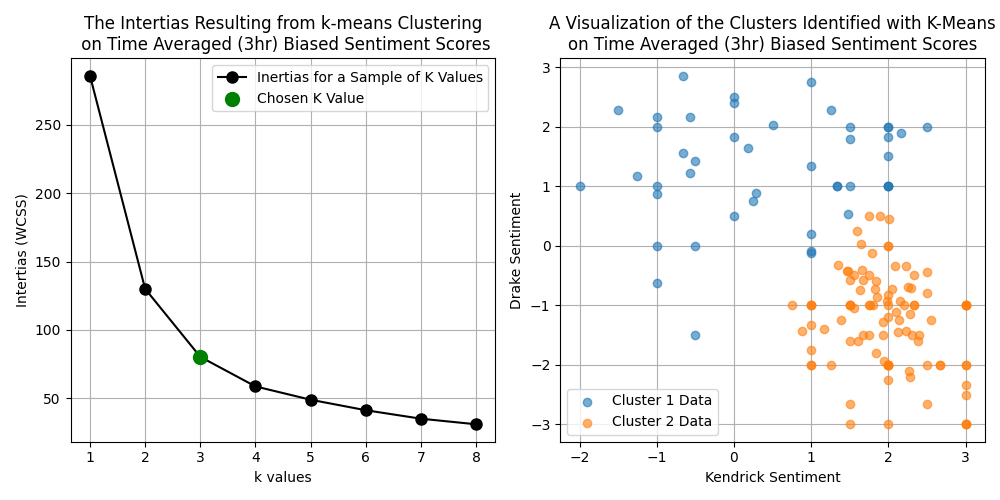

In [30]:
#X DEFINED ABOVE

rangemax = 9
#calculating the intertias for each k
inertias = []
for k in range(1, rangemax):
    km = KMeans(n_clusters=k, n_init=10, random_state=1)
    km.fit(X)
    #appending intertia
    inertias.append(km.inertia_)
print(inertias)

k = range(1, rangemax)
#plotting inertias
plt.close('all')
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))
ax1.plot(k, inertias, marker='o', markersize=8, c='k', zorder=6, label='Inertias for a Sample of K Values')
#From looking at the data, I'm choosing k=4. so, highlighting this point in the plot:
chosenk = 3
chosenk_WCSS = inertias[chosenk-1]
ax1.scatter(chosenk, chosenk_WCSS, marker='o', c='green', s=100, label='Chosen K Value', zorder=100)
ax1.set_xlabel("k values")
ax1.set_ylabel("Intertias (WCSS)")
ax1.set_title("The Intertias Resulting from k-means Clustering\n on Time Averaged (3hr) Biased Sentiment Scores")
ax1.legend()
ax1.grid(True)

#running for k=3
for k in range(1, 3):
    km = KMeans(n_clusters=k, n_init=10, random_state=1)
    km.fit(X)
for i, center in enumerate(km.cluster_centers_):
    mask = km.labels_ == i
    kendrick_scores = combined_biased_dataset['kendrick_score'][mask]
    drake_scores = combined_biased_dataset['drake_score'][mask]
    ax2.scatter(kendrick_scores, drake_scores, alpha=0.6, zorder=5, label=f'Cluster {i+1} Data')

ax2.set_xlabel("Kendrick Sentiment")
ax2.set_ylabel("Drake Sentiment")
ax2.set_title("A Visualization of the Clusters Identified with K-Means\non Time Averaged (3hr) Biased Sentiment Scores")
ax2.legend(loc='best')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

2
{2: 0.5163883224340757, 3: 0.46762831285878476, 4: 0.396816684522918, 5: 0.3841055691879655, 6: 0.34673602898336053, 7: 0.3687907796157094, 8: 0.359970239712772}


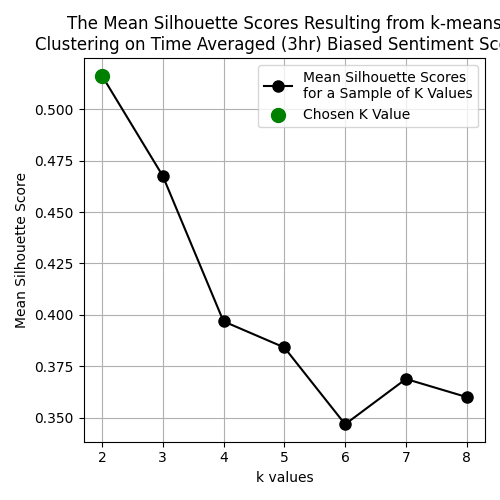

In [23]:
from sklearn.metrics import silhouette_score

#X DEFINED ABOVE

#defining where to store scores
scores = {}
meanscores = []
#looping through a set of ks
for k in range(2, rangemax):
    #modeling the clusters
    model = KMeans(
        n_clusters=k, random_state=42, n_init=10
    ).fit(X)
    #generating the scores and appending them
    scores[k] = silhouette_score(X, model.labels_)
    meanscores.append(scores[k])

#calculating the best k from the maximum of the scores
best_k = max(scores, key=scores.get)
print(best_k)
print(scores)

#plotting the scores:
k = range(2, rangemax)
plt.close('all')
plt.figure(figsize=(5, 5))
plt.plot(k, meanscores, marker='o', markersize=8, c='k', zorder=6, label='Mean Silhouette Scores\nfor a Sample of K Values')

#highlighting the best score
chosenk_silh = meanscores[best_k-2]
plt.scatter(best_k, chosenk_silh, marker='o', c='green', s=100, label='Chosen K Value', zorder=100)

plt.xlabel("k values")
plt.ylabel("Mean Silhouette Score")
plt.title("The Mean Silhouette Scores Resulting from k-means\nClustering on Time Averaged (3hr) Biased Sentiment Scores")
plt.grid(True)
plt.legend(loc='best')
plt.tight_layout()
plt.show()

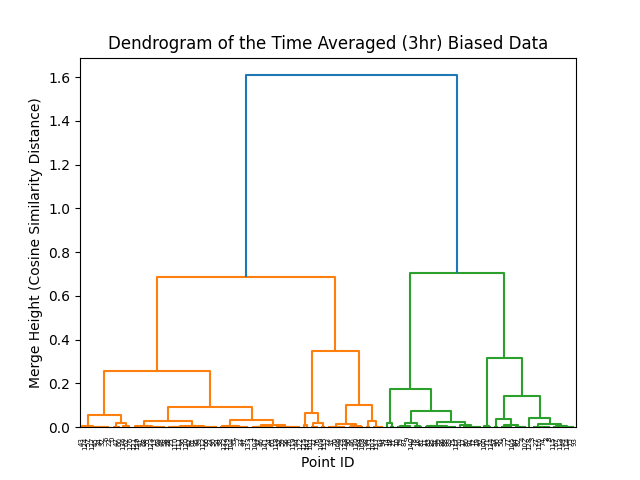

In [34]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
import matplotlib.pyplot as plt

plt.close('all')
Z = linkage(X, method="average", metric='cosine') # or "single", "complete", "ward"
dendrogram(Z)
plt.ylabel("Merge Height (Cosine Similarity Distance)")
plt.xlabel("Point ID")
plt.title("Dendrogram of the Time Averaged (3hr) Biased Data")
plt.show()
labels = fcluster(Z, t=2.5, criterion="distance")